# Fine-tuning Qwen2.5-1.5B-Instruct (LoRA) for oral-screening reports

**Goal:** teach the small local LLM used in the Streamlit app to turn the model's facts into a safe, friendly patient
report in our exact format, so that fewer outputs are rejected by the safety check.

**Method (teacher → student distillation with a safety filter):**
1. **Cases:** generate many synthetic screening cases (result, score, image/metadata share, patient details, SHAP
   directions) and turn each into the **template draft report** with the same code the app uses (`summary_generator.py`).
2. **Teacher:** a larger model (**Qwen2.5-7B-Instruct**, 4-bit) rewrites each draft (few-shot prompt).
   Only rewrites that **pass the safety check** are kept as training targets.
3. **Student:** **Qwen2.5-1.5B-Instruct** is fine-tuned with **LoRA** on (draft → safe report) pairs.
   The loss is computed on the report tokens only.
4. **Evaluation on unseen cases:** base model (zero-shot) vs base + few-shot vs fine-tuned → safety pass rate,
   failure reasons, format compliance, length, speed.
5. **Output:** a small LoRA adapter folder (`qwen_report_lora/`, ~20–40 MB) for the app.

**Kaggle settings:** Accelerator **GPU T4 x2** (or P100) · **Internet ON** (to download the Qwen models). No dataset inputs needed.
Runtime ≈ 1.5–2.5 h with the 7B teacher (set `TEACHER_ID` to the 3B model for ≈ 45 min).

In [1]:
# ============================================================
# 1. CONFIG
# ============================================================
TEACHER_ID   = "Qwen/Qwen2.5-7B-Instruct"     # faster option: "Qwen/Qwen2.5-3B-Instruct" (set TEACHER_4BIT=False)
TEACHER_4BIT = True                           # 7B in 4-bit fits one T4
STUDENT_ID   = "Qwen/Qwen2.5-1.5B-Instruct"   # the model used in the app

N_TRAIN, N_VAL, N_TEST = 600, 60, 100         # synthetic cases (the test cases are never used for training)
GEN_BATCH    = 8                              # teacher batch size
TEACHER_TRIES = 2                             # retries (with sampling) when a teacher output fails the safety check
FALLBACK_TO_TEMPLATE = False                  # True only for a dry run: use the template itself as the target
# Reuse the teacher's reports from an earlier run (skips the slow teacher step). Add that run's output as an input
# and put the path of its training_pairs.jsonl here, e.g. "/kaggle/input/<earlier-run>/qwen_report_finetune/training_pairs.jsonl".
# Leave "" to search /kaggle/input automatically; set to None to always run the teacher.
PAIRS_FILE = "/kaggle/input/notebooks/gokulkrishnabr/qwenb/qwen_report_finetune/training_pairs.jsonl"

LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
EPOCHS, LR, BATCH, GRAD_ACC, MAX_LEN = 3, 2e-4, 2, 8, 1536
MAX_NEW_TOKENS = 450
SEED = 42
OUT_DIR = "/kaggle/working/qwen_report_finetune"

In [2]:
# ============================================================
# 2. INSTALL + IMPORTS
# ============================================================
import subprocess, sys
def _pip(*p): subprocess.run([sys.executable, "-m", "pip", "install", "-q", *p], check=False)
try:
    import peft  # noqa
except ImportError:
    _pip("peft>=0.13")
if TEACHER_4BIT:
    try:
        import bitsandbytes  # noqa
    except ImportError:
        _pip("bitsandbytes>=0.43")

import os, gc, json, time, random, re
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
os.makedirs(OUT_DIR, exist_ok=True); OUT = Path(OUT_DIR)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
# Kaggle ships an old torchao (0.10) that makes peft raise "incompatible version of torchao".
# We don't use torchao at all, so tell peft it is not installed.
try:
    import peft.import_utils as _iu, peft.tuners.lora.torchao as _pt
    _iu.is_torchao_available = lambda: False
    _pt.is_torchao_available = lambda: False
except Exception as e:
    print("torchao patch not needed:", e)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE, "| GPUs:", torch.cuda.device_count())

torch 2.11.0+cu130 | device: cuda | GPUs: 2


## 3. The app's report code (identical copy of `summary_generator.py`)
Same template, same few-shot examples, same safety check as the Streamlit app, so training and deployment match.

In [3]:
%%writefile summary_generator.py
"""
Summary text for one prediction.

1. template_summary(): always works, built only from the model outputs (never invents anything).
   Fixed structure with four headings: Result / What influenced the result / What to do next / Reducing your risk.
   It reports the habit factors (smoking, alcohol, betel quid) that moved the model's score, adds a note when a
   direction contradicts medical knowledge, and adds fixed, checked guidance (next steps and risk reduction).
   It does NOT show "x% from the photo / y% from patient details": that SHAP-based relative attribution is not a
   percentage of the prediction and can be misread by patients (it is shown only under Technical details).
2. LLMRewriter: optional. A small local LLM (Qwen2.5-Instruct) rewrites the report in friendlier language, guided by
   two prompt-based examples (few-shot) or a fine-tuned LoRA adapter. A safety check rejects any rewrite that changes
   the result, adds numbers, drops a habit factor, a risk-factor note, any next step, any risk-reduction point,
   the quitline number or a heading, or makes a diagnosis; then the template report is shown instead.
   The disclaimer is always appended by the code, never left to the LLM.
"""
import re

DISCLAIMER = "This is an AI screening aid, not a diagnosis. Please consult a dentist or oral medicine specialist."
DEFAULT_LLM = "Qwen/Qwen2.5-1.5B-Instruct"     # ~3 GB download the first time; "Qwen/Qwen2.5-0.5B-Instruct" is ~1 GB
HEADINGS = ["**Result**", "**What influenced the result**", "**What to do next**", "**Reducing your risk**"]

FACTOR_KEYS = {"age": "Age", "sex": "Sex", "smoking": "Smoking", "alcohol": "Alcohol", "betel": "Betel quid"}
HABITS = ["Smoking", "Alcohol", "Betel quid"]                    # the only factors described in the summary
HABIT_KEY = {"Smoking": "smoking", "Alcohol": "alcohol", "Betel quid": "betel"}
HABIT_TEXT = {"Smoking": ("not smoking", "smoking"), "Alcohol": ("not drinking alcohol", "drinking alcohol"),
              "Betel quid": ("not chewing betel quid", "chewing betel quid")}
SYNONYMS = {"Smoking": ["smok"], "Alcohol": ["alcohol", "drink"], "Betel quid": ["betel", "quid", "paan", "areca"]}

# Fixed, checked guidance: (sentence, words that must survive any rewrite).
NEXT_STEPS_SUSPICIOUS = [
    ("See a dentist, oral medicine specialist or ENT (ear, nose and throat) doctor as soon as possible, ideally within "
     "2 weeks. Take this report and the photo with you.", ["2 weeks"]),
    ("The specialist will examine your mouth and, if needed, take a small tissue sample (biopsy). Only this can "
     "confirm what the patch is.", ["biopsy"]),
    ("Many suspicious patches turn out to be treatable or not cancer, and problems found early are much easier to "
     "treat. Do not delay the visit.", ["early"]),
    ("Tell the doctor if you notice a sore or patch that has not healed in 3 weeks, a lump, bleeding, pain, numbness, "
     "or difficulty chewing or swallowing.", ["3 weeks"]),
]
NEXT_STEPS_CLEAR = [
    ("This result does not rule out oral disease; a screening model can miss problems.", ["rule out"]),
    ("Keep having regular dental check-ups, and look inside your mouth once a month in good light.", ["check-up"]),
    ("See a dentist if any sore, white or red patch, or lump does not heal in 3 weeks, or if you have pain, bleeding "
     "or numbness.", ["3 weeks"]),
]
HABIT_ADVICE = {
    "Smoking": ("Stopping smoking lowers the risk of oral cancer.", ["smok"]),
    "Betel quid": ("Stopping betel quid, areca nut, gutkha and other chewing tobacco lowers the risk of oral cancer.",
                   ["betel"]),
    "Alcohol": ("Cutting down or stopping alcohol lowers the risk, especially together with tobacco.", ["alcohol"]),
}
QUITLINE = ("Free help to quit tobacco in India: National Tobacco Quitline, 1800-11-2356.", ["1800-11-2356"])
GENERAL_ADVICE = ("Avoiding tobacco in any form, betel quid and alcohol helps keep the risk of oral cancer low.",
                  ["tobacco"])


def _join(items):
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1]


def build_facts(res, patient):
    """Plain facts for the template and the LLM. res comes from Classifier.classify()."""
    given = [h for h in HABITS if patient.get(HABIT_KEY[h]) is not None]
    sh = {h: res["shap_factors"].get(h, 0.0) for h in given}
    up = [h for h, v in sorted(sh.items(), key=lambda kv: -kv[1]) if v > 0.05]
    down = [h for h, v in sorted(sh.items(), key=lambda kv: kv[1]) if v < -0.05]
    yes = [h for h in HABITS if patient.get(HABIT_KEY[h]) == "yes"]
    text = lambda h: HABIT_TEXT[h][h in yes]
    notes = [f"{HABIT_TEXT[h][1].capitalize()} is still a well-known risk factor for oral cancer. It lowered the score "
             f"here only because of patterns in the data the model learned from; it does not mean it is safe."
             for h in down if h in yes]
    if any(h not in yes for h in up):
        notes.append("Some directions reflect patterns in the data the model learned from, not medical causes.")
    steps = NEXT_STEPS_SUSPICIOUS if res["pred"] else NEXT_STEPS_CLEAR
    life = [HABIT_ADVICE[h] for h in yes]
    if any(h in yes for h in ("Smoking", "Betel quid")):
        life.append(QUITLINE)
    if not life:
        life = [GENERAL_ADVICE]
    return dict(
        suspicious=bool(res["pred"]),
        result_word="suspicious" if res["pred"] else "not suspicious",
        result_detail="possible OPMD or oral cancer" if res["pred"] else "healthy or benign",
        probability=round(res["p_final"] * 100),
        habits_given=given, factors_up=up, factors_down=down,
        up_text=[text(h) for h in up], down_text=[text(h) for h in down], notes=notes,
        next_steps=[s for s, _ in steps], next_keys=[k for _, k in steps],
        lifestyle=[s for s, _ in life], life_keys=[k for _, k in life],
    )


def template_summary(f):
    """Markdown report with the same four headings every time."""
    res = (f"The screening model classified the photo as **{f['result_word']}** ({f['result_detail']}), with a model "
           f"score of {f['probability']}%. The coloured area on the photo shows where the model looked most closely"
           + (" and may point to the area that needs checking." if f["suspicious"] else "."))
    if not f["habits_given"]:
        infl = ("No habit details (smoking, alcohol, betel quid) were given, so the result is based on the photo "
                "and any other details entered.")
    else:
        parts = []
        if f["up_text"]:
            parts.append(f"Habits that raised the score: {_join(f['up_text'])}.")
        if f["down_text"]:
            parts.append(f"Habits that lowered the score: {_join(f['down_text'])}.")
        if not parts:
            parts.append("The habit details given had little effect on the score; the result is based mainly on the photo.")
        infl = " ".join(parts + f["notes"])
    out = [HEADINGS[0], res, HEADINGS[1], infl,
           HEADINGS[2], "\n".join(f"- {s}" for s in f["next_steps"]),
           HEADINGS[3], "\n".join(f"- {s}" for s in f["lifestyle"]),
           f"_{DISCLAIMER}_"]
    return "\n\n".join(out)


# ----------------------------------------------------------------------------- few-shot examples
# Two hand-written, prompt-based examples that guide the LLM's rewriting style (not training data).
FEW_SHOT_CASES = [
    (dict(pred=1, p_final=.78, image_share=.62,
          shap_factors={"Age": .3, "Sex": .1, "Smoking": .0, "Alcohol": -.12, "Betel quid": .5}),
     dict(age=58.0, sex="m", smoking="no", alcohol="yes", betel="yes"),
     """**Result**

The screening model classified the photo as **suspicious** (possible OPMD or oral cancer), with a model score of 78%. The coloured area on the photo shows where the model looked most closely, and it may point to the area that needs checking.

**What influenced the result**

Chewing betel quid raised the score. Drinking alcohol lowered it. Please note that drinking alcohol is still a well-known risk factor for oral cancer. It lowered the score here only because of patterns in the data the model learned from, so it does not mean drinking is safe.

**What to do next**

- Please see a dentist, oral medicine specialist or ENT (ear, nose and throat) doctor as soon as possible, ideally within 2 weeks, and take this report and the photo with you.
- The specialist will examine your mouth and, if needed, take a small tissue sample (biopsy). Only this test can confirm what the patch is.
- Many suspicious patches turn out to be treatable or not cancer, and anything found early is much easier to treat, so please do not delay the visit.
- Tell the doctor if you notice a sore or patch that has not healed in 3 weeks, a lump, bleeding, pain, numbness, or difficulty chewing or swallowing.

**Reducing your risk**

- Cutting down or stopping alcohol lowers your risk, especially if you also use tobacco.
- Stopping betel quid, areca nut, gutkha and other chewing tobacco lowers your risk of oral cancer.
- For free help to quit tobacco, call the National Tobacco Quitline on 1800-11-2356."""),
    (dict(pred=0, p_final=.18, image_share=.55,
          shap_factors={"Age": -.3, "Sex": -.1, "Smoking": .2, "Alcohol": .0, "Betel quid": -.2}),
     dict(age=27.0, sex="f", smoking="yes", alcohol=None, betel="no"),
     """**Result**

The screening model classified the photo as **not suspicious** (healthy or benign), with a model score of 18%. The coloured area on the photo shows where the model looked most closely.

**What influenced the result**

Smoking raised the score, and not chewing betel quid lowered it.

**What to do next**

- This result does not rule out oral disease, because a screening model can miss problems.
- Keep having regular dental check-ups, and look inside your mouth once a month in good light.
- See a dentist if any sore, white or red patch, or lump does not heal in 3 weeks, or if you have pain, bleeding or numbness.

**Reducing your risk**

- Smoking is a risk factor for oral cancer, and stopping smoking lowers your risk.
- For free help to quit tobacco, call the National Tobacco Quitline on 1800-11-2356."""),
]


def build_messages(draft, system, few_shot=True):
    """Chat messages for the LLM: system rules, optional worked examples, then the real draft."""
    msgs = [{"role": "system", "content": system}]
    if few_shot:
        for res, patient, answer in FEW_SHOT_CASES:
            ex = template_summary(build_facts(res, patient)).replace(f"_{DISCLAIMER}_", "").strip()
            msgs += [{"role": "user", "content": f"Draft report:\n\n{ex}"}, {"role": "assistant", "content": answer}]
    msgs.append({"role": "user", "content": f"Draft report:\n\n{draft}"})
    return msgs


# ----------------------------------------------------------------------------- safety check
# Phrases that would make a diagnosis, promise an outcome, reassure falsely or mention treatment. Precise patterns,
# so ordinary sentences like "you don't have to worry" or "definitely see a dentist" are not caught.
BANNED = [
    r"\byou (?:\w+ ){0,2}have (?:oral |mouth )?cancer", r"\byou (?:do not|don't|dont) have (?:oral |mouth )?cancer",
    r"\b(?:is|are|it's) (?:definitely|certainly|surely) (?:not )?(?:cancer|malignant|benign)",
    r"\bdiagnosed with\b", r"\bthe diagnosis is\b", r"\bguarantee", r"\bgood news\b", r"\bnothing to worry",
    r"\bno need to (?:see|consult|visit|worry)", r"\bchemotherapy\b", r"\bradiotherapy\b",
    r"\bradiation therapy\b", r"\bsurgery\b", r"\bmalignant tumou?r", r"\bterminal\b", r"\bfatal\b", r"\bdeadly\b",
]


def is_safe(text, facts):
    """True if an LLM rewrite keeps every fact, step and warning of the template and adds nothing unsupported."""
    t = text.lower()
    for pat in BANNED:
        m = re.search(pat, t)
        if m:
            return False, f"contains a diagnostic, reassuring or alarming phrase: '{m.group(0)}'"
    if "%" in text.replace(f"{facts['probability']}%", ""):
        return False, "added a percentage that is not the model score"
    allowed = {str(facts["probability"])} | set(re.findall(r"\d+", " ".join(facts["next_steps"] + facts["lifestyle"])))
    nums = set(re.findall(r"\d+", text))
    if not nums <= allowed:
        return False, f"added numbers not in the results: {sorted(nums - allowed)}"
    says_not = bool(re.search(r"\bnot (?:appear |look |seem )?(?:to be )?suspicious|\bnon-suspicious", t))
    if facts["suspicious"] and (says_not or "suspicious" not in t):
        return False, "changed the result"
    if not facts["suspicious"] and not says_not:
        return False, "changed the result"
    if "screening" not in t:
        return False, "did not say the result comes from a screening model"
    for h in HEADINGS:
        if h.strip("*").lower() not in t:
            return False, f"left out the heading {h.strip('*')}"
    for h in facts["factors_up"] + facts["factors_down"]:
        if not any(w in t for w in SYNONYMS[h]):
            return False, f"left out the habit '{h}'"
    if any("risk factor" in n for n in facts["notes"]) and "risk factor" not in t:
        return False, "left out the note that a habit is still a risk factor"
    if facts["notes"] and "pattern" not in t:
        return False, "left out the note that directions come from patterns in the data"
    for step, keys in zip(facts["next_steps"], facts["next_keys"]):
        if not all(k.lower() in t for k in keys):
            return False, f"left out the next step '{step[:45]}...'"
    for tip, keys in zip(facts["lifestyle"], facts["life_keys"]):
        if not all(k.lower() in t for k in keys):
            return False, f"left out the risk-reduction point '{tip[:45]}...'"
    if len(text.split()) > 330:
        return False, "is too long"
    return True, ""


# ----------------------------------------------------------------------------- LLM
class LLMRewriter:
    """Talks to llm_worker.py, which loads a small instruction-tuned model with Hugging Face transformers
    (downloaded once, then offline). It runs in a separate process so PyTorch never shares a process with XGBoost."""

    SYSTEM = ("You write short, kind, easy-to-read oral screening reports for patients in India. "
              "You are given a draft report made from an AI screening model's results and checked medical guidance. "
              "Rewrite it in calm, neutral, simple English that a non-medical person understands. Rules: "
              "use ONLY the facts and advice in the draft; do not add new numbers, percentages, diseases, tests, "
              "treatments or causes; make clear the result comes from an AI screening model, not a diagnosis; "
              "never say the person has or does not have cancer; do not say 'good news' or give false reassurance; "
              "keep the result word exactly as given ('suspicious' or 'not suspicious'); mention every habit that is "
              "named and whether it raised or lowered the score; keep every note about risk factors and data "
              "patterns; keep every next step, every risk-reduction point and the quitline number; always use exactly "
              "these four bold headings in this order: **Result**, **What influenced the result**, **What to do next**, "
              "**Reducing your risk**, with short bullet points under the last two; at most 250 words.")

    def __init__(self, model_id=DEFAULT_LLM, adapter_dir=None):
        """adapter_dir: folder with a fine-tuned LoRA adapter (from the Kaggle notebook); None = auto-detect
        models/llm/qwen_report_lora next to this file. With an adapter, few-shot examples are not needed."""
        import subprocess, sys, json
        from pathlib import Path
        self.json = json
        here = Path(__file__).resolve().parent
        if adapter_dir is None:
            cand = here / "models" / "llm" / "qwen_report_lora"
            adapter_dir = cand if (cand / "adapter_config.json").exists() else None
        worker = here / "llm_worker.py"
        cmd = [sys.executable, str(worker), model_id] + ([str(adapter_dir)] if adapter_dir else [])
        self.proc = subprocess.Popen(cmd, stdin=subprocess.PIPE, stdout=subprocess.PIPE, text=True, bufsize=1)
        first = self._read()
        if "error" in first:
            raise RuntimeError(first["error"])
        self.fine_tuned = bool(first.get("adapter"))

    def _read(self):
        while True:
            line = self.proc.stdout.readline()
            if not line:
                raise RuntimeError("the language model process stopped (see the Terminal for details)")
            line = line.strip()
            if line.startswith("{"):
                try:
                    return self.json.loads(line)
                except ValueError:
                    pass

    def _ask(self, messages):
        self.proc.stdin.write(self.json.dumps({"messages": messages}) + "\n")
        self.proc.stdin.flush()
        return self._read()

    def rewrite(self, template, facts, attempts=2):
        """Returns (text_to_show, note, rejected_llm_text). Retries once with feedback if the safety check fails."""
        draft = template.replace(f"_{DISCLAIMER}_", "").strip()
        msgs = build_messages(draft, self.SYSTEM, few_shot=not self.fine_tuned)
        rejected, why = "", ""
        for i in range(attempts):
            reply = self._ask(msgs)
            if "error" in reply:
                return template, f"Language model error ({reply['error']}); showing the standard summary.", rejected
            text = reply["text"].replace(DISCLAIMER, "").strip()
            ok, why = is_safe(text, facts)
            if ok:
                return f"{text}\n\n_{DISCLAIMER}_", ("" if i == 0 else "(accepted on the second try)"), ""
            rejected = text
            msgs = msgs + [{"role": "assistant", "content": text},
                           {"role": "user", "content": f"That version was rejected because it {why}. "
                                                       f"Write the report again from the draft and follow every rule exactly."}]
        return template, f"LLM text rejected ({why}); showing the standard summary.", rejected

Writing summary_generator.py


In [4]:
import importlib, summary_generator as S
importlib.reload(S)
SYSTEM = S.LLMRewriter.SYSTEM
print("Safety rules loaded:", len(S.BANNED), "banned patterns | few-shot examples:", len(S.FEW_SHOT_CASES))

Safety rules loaded: 17 banned patterns | few-shot examples: 2


## 4. Synthetic screening cases → draft reports
Each case mimics one app prediction: suspicious or not, a score, how much came from the photo, which patient details
were given (some left unknown), and random SHAP directions, including medically "odd" ones such as *smokes lowered the score*,
so the model learns to keep the risk-factor note.

In [5]:
def random_case(rng):
    patient = dict(age=float(rng.integers(18, 86)) if rng.random() > .15 else None,
                   sex=rng.choice(["m", "f"]) if rng.random() > .15 else None,
                   smoking=rng.choice(["yes", "no"]) if rng.random() > .15 else None,
                   alcohol=rng.choice(["yes", "no"]) if rng.random() > .15 else None,
                   betel=rng.choice(["yes", "no"]) if rng.random() > .15 else None)
    suspicious = rng.random() < .5
    p = float(rng.uniform(.5, .99) if suspicious else rng.uniform(.01, .49))
    any_known = any(v is not None for v in patient.values())
    share = float(rng.uniform(.3, .95)) if any_known else 1.0
    shap = {k: float(rng.normal(0, .35)) for k in ["Age", "Sex", "Smoking", "Alcohol", "Betel quid"]}
    res = dict(pred=int(suspicious), p_final=p, image_share=share, shap_factors=shap)
    return res, patient


rng = np.random.default_rng(SEED)
CASES = [random_case(rng) for _ in range(N_TRAIN + N_VAL + N_TEST)]
FACTS = [S.build_facts(r, p) for r, p in CASES]
DRAFTS = [S.template_summary(f).replace(f"_{S.DISCLAIMER}_", "").strip() for f in FACTS]
split = ["train"] * N_TRAIN + ["val"] * N_VAL + ["test"] * N_TEST
assert all(S.is_safe(d, f)[0] for d, f in zip(DRAFTS, FACTS)), "template drafts must pass the safety check"
print(f"{len(DRAFTS)} cases | suspicious: {np.mean([f['suspicious'] for f in FACTS]):.0%} | "
      f"with a risk-factor note: {np.mean([bool(f['notes']) for f in FACTS]):.0%} | "
      f"with lifestyle advice: {np.mean([bool(f['lifestyle']) for f in FACTS]):.0%}")
print("\nExample draft:\n", DRAFTS[0][:900])

760 cases | suspicious: 52% | with a risk-factor note: 78% | with lifestyle advice: 100%

Example draft:
 **Result**

The screening model classified the photo as **suspicious** (possible OPMD or oral cancer), with a model score of 72%. The coloured area on the photo shows where the model looked most closely and may point to the area that needs checking.

**What influenced the result**

Habits that raised the score: smoking and drinking alcohol. Habits that lowered the score: not chewing betel quid.

**What to do next**

- See a dentist, oral medicine specialist or ENT (ear, nose and throat) doctor as soon as possible, ideally within 2 weeks. Take this report and the photo with you.
- The specialist will examine your mouth and, if needed, take a small tissue sample (biopsy). Only this can confirm what the patch is.
- Many suspicious patches turn out to be treatable or not cancer, and problems found early are much easier to treat. Do not delay the visit.
- Tell the doctor if you notice a

## 5. Batched generation helper

In [6]:
def load(model_id, four_bit=False):
    tok = AutoTokenizer.from_pretrained(model_id)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    kw = dict(dtype=torch.float16 if DEVICE == "cuda" else torch.float32)
    if four_bit and DEVICE == "cuda":
        from transformers import BitsAndBytesConfig
        kw = dict(quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16,
                                                         bnb_4bit_quant_type="nf4"))
    model = AutoModelForCausalLM.from_pretrained(model_id, device_map="auto" if DEVICE == "cuda" else None, **kw).eval()
    return tok, model


@torch.no_grad()
def generate(tok, model, list_of_messages, batch=8, sample=False):
    outs, secs = [], []
    for i in range(0, len(list_of_messages), batch):
        prompts = [tok.apply_chat_template(m, add_generation_prompt=True, tokenize=False) for m in list_of_messages[i:i + batch]]
        enc = tok(prompts, return_tensors="pt", padding=True).to(model.device)
        t0 = time.time()
        gen = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, pad_token_id=tok.pad_token_id,
                             do_sample=sample, temperature=0.7 if sample else None, top_p=0.9 if sample else None,
                             repetition_penalty=1.05)
        dt = (time.time() - t0) / len(prompts)
        for g in gen:
            outs.append(tok.decode(g[enc["input_ids"].shape[1]:], skip_special_tokens=True).strip().replace(S.DISCLAIMER, "").strip())
            secs.append(dt)
        print(f"  {min(i + batch, len(list_of_messages))}/{len(list_of_messages)}", end="\r")
    print()
    return outs, secs

## 6. Teacher writes the training reports (kept only if they pass the safety check)

In [7]:
def find_pairs():
    if PAIRS_FILE is None:
        return None
    if PAIRS_FILE:
        return Path(PAIRS_FILE)
    for d, _, fs in os.walk("/kaggle/input", followlinks=True):
        if "training_pairs.jsonl" in fs:
            return Path(d) / "training_pairs.jsonl"
    return None


targets, reasons = {}, {}
pf = find_pairs()
if pf is not None and pf.exists():
    P = pd.read_json(pf, lines=True)
    for _, r in P.iterrows():
        i = int(r["i"])
        if i < len(DRAFTS) and r["draft"] == DRAFTS[i] and S.is_safe(r["target"], FACTS[i])[0]:
            targets[i] = r["target"]                 # same case, same draft, still passes the current safety check
    idx = [i for i, s in enumerate(split) if s in ("train", "val")]
    teacher_pass = len([i for i in idx if i in targets]) / len(idx)
    print(f"Loaded {len(P)} teacher reports from {pf}; kept {len(targets)} that match this run's cases "
          f"and pass the safety check -> teacher step skipped.")
    pd.DataFrame([dict(i=i, split=split[i], draft=DRAFTS[i], target=targets[i]) for i in sorted(targets)]).to_json(
        OUT / "training_pairs.jsonl", orient="records", lines=True)
    if len(targets) < min(50, len(idx) // 2):
        print("Too few usable pairs (different settings or report rules?) -> running the teacher instead.")
        targets = {}
if not targets:
  t0 = time.time()
  tok_t, teacher = load(TEACHER_ID, TEACHER_4BIT)
  idx = [i for i, s in enumerate(split) if s in ("train", "val")]
  todo = idx
  for attempt in range(TEACHER_TRIES):
      msgs = [S.build_messages(DRAFTS[i], SYSTEM, few_shot=True) for i in todo]
      outs, _ = generate(tok_t, teacher, msgs, GEN_BATCH, sample=attempt > 0)
      still = []
      for i, o in zip(todo, outs):
          ok, why = S.is_safe(o, FACTS[i])
          if ok:
              targets[i] = o
          else:
              reasons[i] = why; still.append(i)
      print(f"attempt {attempt + 1}: kept {len(todo) - len(still)}/{len(todo)}")
      todo = still
      if not todo:
          break
  if FALLBACK_TO_TEMPLATE:
      for i in todo:
          targets[i] = DRAFTS[i]
  teacher_pass = len([i for i in idx if i in targets and targets[i] != DRAFTS[i]]) / len(idx)
  print(f"Teacher outputs passing the safety check: {teacher_pass:.0%} | training pairs: {len(targets)} "
        f"| time {(time.time() - t0) / 60:.1f} min")
  print("Most common rejection reasons:", pd.Series([re.sub(r":.*", "", r) for r in reasons.values()]).value_counts().head(5).to_dict())
  pd.DataFrame([dict(i=i, split=split[i], draft=DRAFTS[i], target=targets[i]) for i in sorted(targets)]).to_json(
      OUT / "training_pairs.jsonl", orient="records", lines=True)
  del teacher; gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None

Loaded 658 teacher reports from /kaggle/input/notebooks/gokulkrishnabr/qwenb/qwen_report_finetune/training_pairs.jsonl; kept 658 that match this run's cases and pass the safety check -> teacher step skipped.


## 7. LoRA fine-tuning of the student (loss on the report tokens only)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

train pairs 598 | val pairs 60 | max tokens 1031


... (3 outputs left out)

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


Epoch,Training Loss,Validation Loss
1,0.024575,0.017925
2,0.015774,0.013124
3,0.010949,0.012266


training time 20.1 min


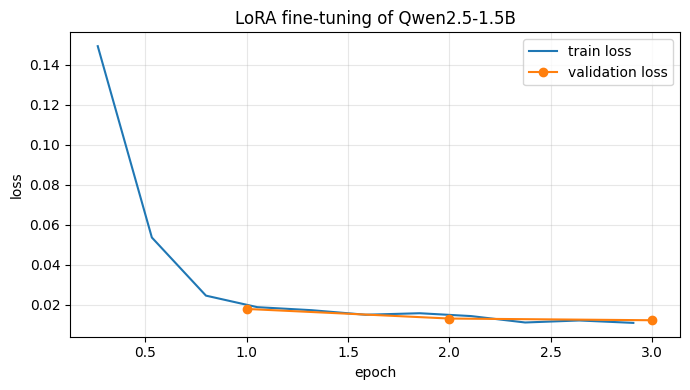

In [8]:
from peft import LoraConfig, get_peft_model
from transformers import Trainer, TrainingArguments

tok_s = AutoTokenizer.from_pretrained(STUDENT_ID)
if tok_s.pad_token is None:
    tok_s.pad_token = tok_s.eos_token


def encode(i):
    prompt = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": f"Draft report:\n\n{DRAFTS[i]}"}]
    p_txt = tok_s.apply_chat_template(prompt, add_generation_prompt=True, tokenize=False)
    f_txt = tok_s.apply_chat_template(prompt + [{"role": "assistant", "content": targets[i]}], tokenize=False)
    p_ids = tok_s(p_txt, add_special_tokens=False)["input_ids"]
    full = tok_s(f_txt, add_special_tokens=False)["input_ids"][:MAX_LEN]
    labels = [-100] * len(p_ids) + full[len(p_ids):]           # learn only the report, not the prompt
    return dict(input_ids=full, labels=labels[:len(full)])


class DS(torch.utils.data.Dataset):
    def __init__(self, ids): self.items = [encode(i) for i in ids]
    def __len__(self): return len(self.items)
    def __getitem__(self, k): return self.items[k]


def collate(batch):
    n = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), n), tok_s.pad_token_id); lab = torch.full((len(batch), n), -100); att = torch.zeros((len(batch), n), dtype=torch.long)
    for k, b in enumerate(batch):
        L = len(b["input_ids"]); ids[k, :L] = torch.tensor(b["input_ids"]); lab[k, :L] = torch.tensor(b["labels"]); att[k, :L] = 1
    return dict(input_ids=ids, labels=lab, attention_mask=att)


tr_ids = [i for i in sorted(targets) if split[i] == "train"]
va_ids = [i for i in sorted(targets) if split[i] == "val"]
ds_tr, ds_va = DS(tr_ids), DS(va_ids)
print(f"train pairs {len(ds_tr)} | val pairs {len(ds_va)} | max tokens {max(len(x['input_ids']) for x in ds_tr.items)}")

student = AutoModelForCausalLM.from_pretrained(STUDENT_ID, dtype=torch.float16 if DEVICE == "cuda" else torch.float32,
                                               device_map={"": 0} if DEVICE == "cuda" else None)
student.gradient_checkpointing_enable(); student.enable_input_require_grads(); student.config.use_cache = False
student = get_peft_model(student, LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                                             target_modules=LORA_TARGETS, task_type="CAUSAL_LM"))
for p in student.parameters():
    if p.requires_grad:
        p.data = p.data.float()                      # LoRA weights in fp32 (stable fp16 training on T4)
student.print_trainable_parameters()

steps_total = int(np.ceil(len(ds_tr) / (BATCH * GRAD_ACC))) * EPOCHS
args = TrainingArguments(output_dir=str(OUT / "checkpoints"), num_train_epochs=EPOCHS, learning_rate=LR,
                         per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
                         gradient_accumulation_steps=GRAD_ACC, lr_scheduler_type="cosine", warmup_steps=max(1, int(0.05 * steps_total)),
                         logging_steps=5, eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
                         load_best_model_at_end=True, metric_for_best_model="eval_loss",
                         fp16=DEVICE == "cuda", report_to="none", seed=SEED, remove_unused_columns=False)
trainer = Trainer(model=student, args=args, train_dataset=ds_tr, eval_dataset=ds_va, data_collator=collate)
t0 = time.time(); trainer.train(); print(f"training time {(time.time() - t0) / 60:.1f} min")

ADAPTER = OUT / "qwen_report_lora"
student.save_pretrained(ADAPTER); tok_s.save_pretrained(ADAPTER)
json.dump(dict(base_model=STUDENT_ID, teacher=TEACHER_ID, lora_r=LORA_R, lora_alpha=LORA_ALPHA, epochs=EPOCHS, lr=LR,
               train_pairs=len(ds_tr), val_pairs=len(ds_va), teacher_pass_rate=teacher_pass),
          open(ADAPTER / "training_info.json", "w"), indent=2)

h = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(figsize=(7, 4))
if "loss" in h: ax.plot(h.dropna(subset=["loss"])["epoch"], h.dropna(subset=["loss"])["loss"], label="train loss")
if "eval_loss" in h: ax.plot(h.dropna(subset=["eval_loss"])["epoch"], h.dropna(subset=["eval_loss"])["eval_loss"], "o-", label="validation loss")
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title("LoRA fine-tuning of Qwen2.5-1.5B"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); fig.savefig(OUT / "lora_training_curve.png", dpi=200); plt.show()

## 8. Evaluation on unseen test cases: base vs few-shot vs fine-tuned

  100/100
  100/100
  100/100


,safety_pass_rate,format_ok,mean_words,sec_per_report
system,,,,
Base (zero-shot),0.41,0.86,159.03,1.645
Base + few-shot,0.93,1.00,192.77,2.516
Fine-tuned (LoRA),1.00,1.00,192.89,3.284


Rejection reasons (count of test cases):


reason,did not say the result comes from a screening model,left out the note that directions come from patterns in the data,left out the note that a habit is still a risk factor,left out the habit 'Alcohol',left out the next step 'This result does not rule out oral disease; a...',changed the result,"left out the next step 'See a dentist, oral medicine specialist or EN...'","left out the next step 'See a dentist if any sore, white or red patch...'",left out the habit 'Smoking'
system,,,,,,,,,
Base (zero-shot),8,17,16,1,4,9,3,1,0
Base + few-shot,0,2,4,0,0,0,0,0,1


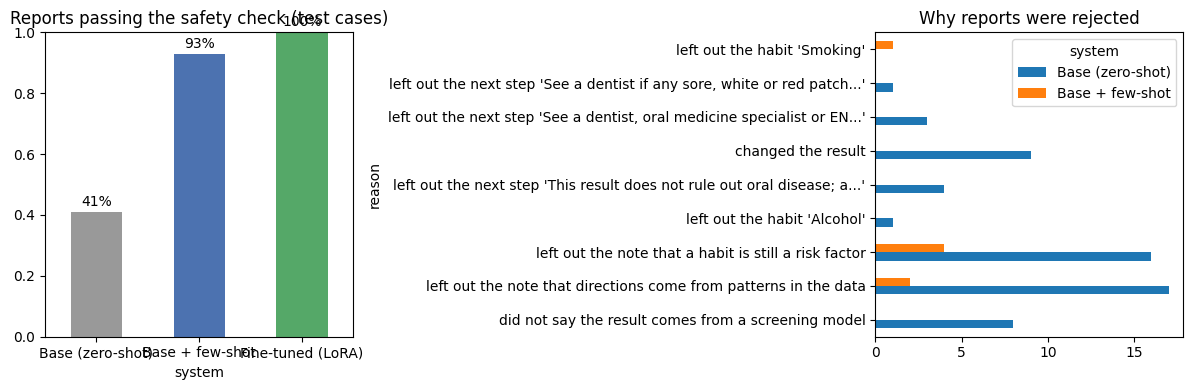

Example fine-tuned report (test case):

**Result**

The screening model classified the photo as **suspicious** (possible OPMD or oral cancer), with a model score of 81%. The coloured area on the photo shows where the model looked most closely and may point to the area that needs checking.

**What influenced the result**

Drinking alcohol raised the score.

**What to do next**

- See a dentist, oral medicine specialist or ENT (ear, nose and throat) doctor as soon as possible, ideally within 2 weeks. Take this report and the photo with you.
- The specialist will examine your mouth and, if needed, take a small tissue sample (biopsy). Only this can confirm what the patch is.
- Many suspicious patches turn out to be treatable or not cancer, and problems found early are much easier to treat. Do not delay the visit.
- Tell the doctor if you notice a sore or patch that has not healed in 3 weeks, a lump, bleeding, pain, numbness, or difficulty chewing or swallowing.

**Reducing your risk**

- C

In [9]:
test_ids = [i for i, s in enumerate(split) if s == "test"]
HEADS = ["**Result**", "**What influenced the result**", "**What to do next**", "**Reducing your risk**"]


def evaluate(name, outs, secs):
    rows = []
    for i, o, t in zip(test_ids, outs, secs):
        ok, why = S.is_safe(o, FACTS[i])
        need = [h for h in HEADS if h != "**Reducing your risk**" or FACTS[i]["lifestyle"]]
        if not FACTS[i]["factors_up"] and not FACTS[i]["factors_down"] and not FACTS[i]["notes"]:
            need = [h for h in need if h != "**What influenced the result**"]
        rows.append(dict(system=name, case=i, passed=ok, reason=re.sub(r":.*", "", why) if not ok else "",
                         format_ok=all(h in o for h in need), words=len(o.split()), sec=t, text=o))
    return rows


results = []
student.eval(); student.config.use_cache = True
tok_s.padding_side = "left"
with student.disable_adapter():
    o, s_ = generate(tok_s, student, [[{"role": "system", "content": SYSTEM}, {"role": "user", "content": f"Draft report:\n\n{DRAFTS[i]}"}] for i in test_ids], GEN_BATCH)
    results += evaluate("Base (zero-shot)", o, s_)
    o, s_ = generate(tok_s, student, [S.build_messages(DRAFTS[i], SYSTEM, few_shot=True) for i in test_ids], GEN_BATCH)
    results += evaluate("Base + few-shot", o, s_)
o, s_ = generate(tok_s, student, [[{"role": "system", "content": SYSTEM}, {"role": "user", "content": f"Draft report:\n\n{DRAFTS[i]}"}] for i in test_ids], GEN_BATCH)
results += evaluate("Fine-tuned (LoRA)", o, s_)

R = pd.DataFrame(results); R.to_csv(OUT / "test_outputs.csv", index=False)
summary = R.groupby("system", sort=False).agg(safety_pass_rate=("passed", "mean"), format_ok=("format_ok", "mean"),
                                              mean_words=("words", "mean"), sec_per_report=("sec", "mean")).round(3)
display(summary); summary.to_csv(OUT / "comparison_table.csv")
fails = R[~R.passed].groupby(["system", "reason"], sort=False).size().unstack(fill_value=0)
print("Rejection reasons (count of test cases):"); display(fails)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
summary["safety_pass_rate"].plot.bar(ax=ax[0], color=["#999999", "#4C72B0", "#55A868"], rot=0)
ax[0].set_ylim(0, 1); ax[0].set_title("Reports passing the safety check (test cases)")
for k, v in enumerate(summary["safety_pass_rate"]): ax[0].text(k, v + .02, f"{v:.0%}", ha="center")
if len(fails): fails.T.plot.barh(ax=ax[1]); ax[1].set_title("Why reports were rejected")
plt.tight_layout(); fig.savefig(OUT / "llm_comparison.png", dpi=200); plt.show()

ex = R[(R.system == "Fine-tuned (LoRA)") & R.passed].head(1)
if len(ex):
    print("Example fine-tuned report (test case):\n"); print(ex.iloc[0]["text"])

## 9. Download and use in the app

In [10]:
import shutil
shutil.make_archive(str(OUT / "qwen_report_lora"), "zip", OUT / "qwen_report_lora")
print("Download from the Output panel:", OUT / "qwen_report_lora.zip")
print("""
In the app on your Mac:
  1. Unzip into   Oral_app/models/llm/qwen_report_lora/   (the folder must contain adapter_config.json)
  2. pip install peft        (already in requirements.txt)
  3. Restart:  streamlit run app.py   and tick 'Write the summary with AI'
     The caption will say: 'Qwen2.5-1.5B-Instruct + fine-tuned report adapter'.
""")

Download from the Output panel: /kaggle/working/qwen_report_finetune/qwen_report_lora.zip

In the app on your Mac:
  1. Unzip into   Oral_app/models/llm/qwen_report_lora/   (the folder must contain adapter_config.json)
  2. pip install peft        (already in requirements.txt)
  3. Restart:  streamlit run app.py   and tick 'Write the summary with AI'
     The caption will say: 'Qwen2.5-1.5B-Instruct + fine-tuned report adapter'.

